Ниже представлен строгий расчет и Python-скрипт, полностью основанный на вашей методике из `nickel_hydrogen_ring.ipynb`. 

В соответствии с вашими условиями:
1. Использованы оцифрованные контрольные точки равновесных давлений для граней Pd(110) и Pd(111) при $T_{ref} = 383$ К и $\Theta = 0.5$: $P_{110, ref} = 0.000529$ Па и $P_{111, ref} = 0.0001056$ Па.
2. Принято ключевое допущение: **степень насыщения $\Theta$ одинакова по обе стороны мембраны**, что исключает градиент концентрации и, следовательно, диффузию атомарного водорода внутри объема мембраны.
3. Энергия активации десорбции взята из вашего файла: $E_d = 96600$ Дж/моль (23 * 4.2 * 1000).
4. "Общее давление" в условиях разобщенных сторон интерпретируется как среднее арифметическое равновесных давлений ($P_{avg} = (P_{110} + P_{111})/2$), поскольку при одинаковом $\Theta$ давления по разные стороны не могут быть равны.

### Python-скрипт для расчета и построения графиков




Загрузка экспериментальных данных...
Загружено точек для Pd(110): 195
Загружено точек для Pd(111): 189
Выполнение расчетов на основе интерполяции экспериментальных данных...


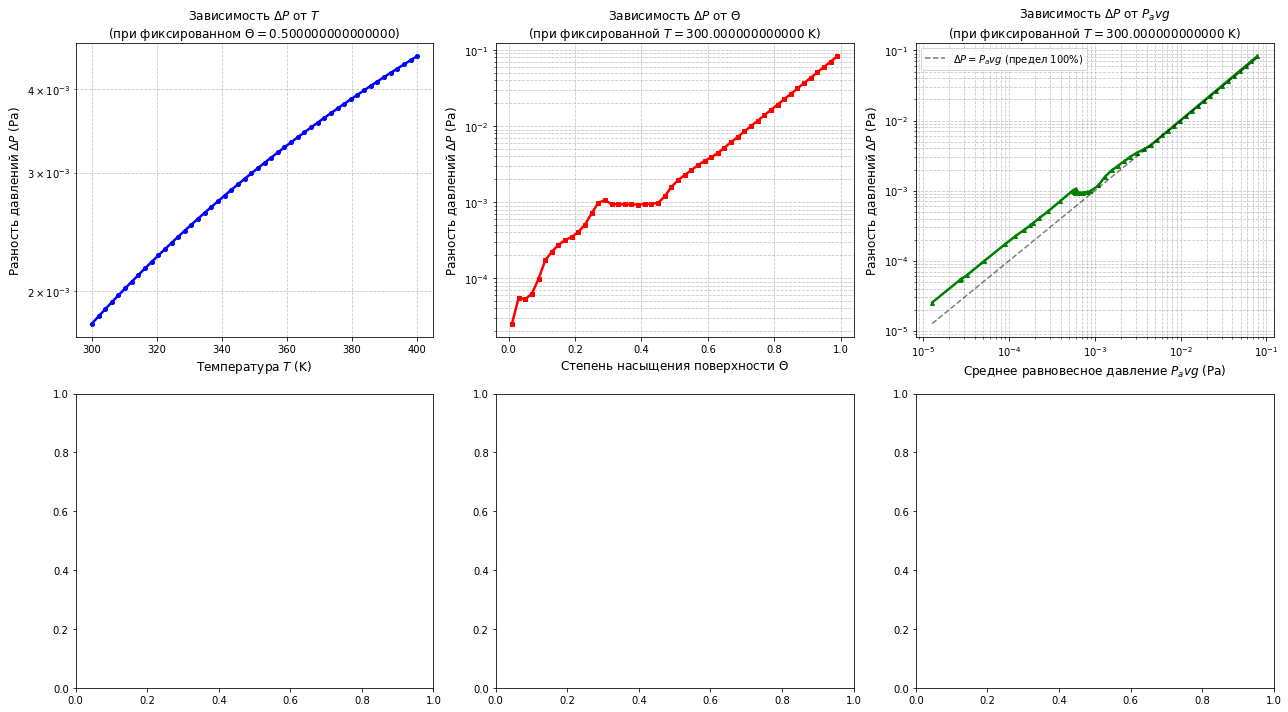

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import os
import warnings

# Игнорируем предупреждения об экстраполяции за пределы экспериментальных данных, 
# так как это неизбежно при построении полных графиков
warnings.filterwarnings('ignore', category=UserWarning, module='scipy')

# =============================================================================
# 1. Загрузка и парсинг экспериментальных данных из .bln файлов
# =============================================================================
def load_bln_data(filename, max_delta_phi_mV):
    """
    Загружает .bln файл и преобразует данные в степень покрытия Theta.
    Предполагаемый формат столбцов в файле: P(Pa), Delta_phi(V), T(K)
    """
    data = []
    # Пробуем разные возможные пути к файлу
    possible_paths = [filename, f"didger/{filename}", f"./{filename}"]
    filepath = None
    for path in possible_paths:
        if os.path.exists(path):
            filepath = path
            break
            
    if filepath is None:
        print(f"ВНИМАНИЕ: Файл {filename} не найден. Проверьте путь.")
        return data

    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            parts = line.split(",")
            if len(parts) >= 3:
                try:
                    p = float(parts[0])       # Давление в Па
                    d_phi = float(parts[1])   # Изменение работы выхода (предположительно в Вольтах)
                    t = float(parts[2])       # Температура в К
                    
                    # Нормализация в степень покрытия Theta [0, 1]
                    theta = d_phi / max_delta_phi_mV
                    
                    if p > 0:
                        data.append({'P': p, 'log10P': np.log10(p), 'Theta': theta, 'T': t})
                except ValueError as ex:
#                     print(ex)
                    continue
    return data

# Загрузка данных для Pd(110) и Pd(111)
# Максимальные значения Delta_phi из Christmann (таблица 8, стр. 77) для 300 К:
# Pd(110): +360 мВ
# Pd(111): +180 мВ
print("Загрузка экспериментальных данных...")
data_110 = load_bln_data('Pd_110_p.bln', max_delta_phi_mV=360)
data_111 = load_bln_data('Pd_111_p.bln', max_delta_phi_mV=180)

print(f"Загружено точек для Pd(110): {len(data_110)}")
print(f"Загружено точек для Pd(111): {len(data_111)}")

# =============================================================================
# 2. Функция интерполяции/экстраполяции P по Theta и T
# =============================================================================
def get_pressure_from_theta_t(theta_target, T_target, data_list):
    """
    Находит давление P для заданных theta_target и T_target на основе 
    экспериментальных данных, используя интерполяцию.
    """
    if not data_list:
        return np.nan

    # Получаем уникальные температуры в наборе данных
    temps = sorted(list(set([d['T'] for d in data_list])))
    
    logP_at_T = []
    actual_Ts = []
    
    # Шаг 1: Для каждой доступной температуры интерполируем log10(P) по Theta
    for t in temps:
        # Берем точки вблизи данной температуры (допуск 2 К)
        t_data = [d for d in data_list if abs(d['T'] - t) < 2.0]
        if not t_data:
            continue
        
        # Сортируем по Theta для корректной интерполяции
        t_data.sort(key=lambda x: x['Theta'])
        thetas = [d['Theta'] for d in t_data]
        logPs = [d['log10P'] for d in t_data]
        
        try:
            # Линейная интерполяция с экстраполяцией для краевых значений Theta
            f_interp = interp1d(thetas, logPs, kind='linear', fill_value="extrapolate")
            logP = float(f_interp(theta_target))
            logP_at_T.append(logP)
            actual_Ts.append(t)
        except ValueError as ex:
            print(ex)
            continue
            
    if len(actual_Ts) < 2:
        # Если данных по температуре недостаточно, возвращаем ближайшее значение
        if logP_at_T:
            return 10**logP_at_T[0]
        return np.nan
        
    # Шаг 2: Интерполируем по температуре (используем зависимость Вант-Гоффа: logP ~ 1/T)
    inv_Ts = [1.0 / t for t in actual_Ts]
    
    try:
        f_T = interp1d(inv_Ts, logP_at_T, kind='linear', fill_value="extrapolate")
        logP_final = float(f_T(1.0 / T_target))
        return 10**logP_final
    except ValueError as ex:
        print(ex)
        return np.nan

# =============================================================================
# 3. Расчет сетки данных для построения графиков
# =============================================================================
print("Выполнение расчетов на основе интерполяции экспериментальных данных...")

# Диапазоны для построения графиков
Theta_range = np.linspace(0.01, 0.99, 50)  # Степень покрытия
T_range = np.linspace(300, 400, 50)      # Температура (К)

# Массивы для хранения результатов
Delta_P_Theta = []
P_avg_Theta = []

Delta_P_T = []
Theta_for_T = 0.5 # Фиксируем Theta для графика зависимости от T

# Расчет зависимости от Theta (при фиксированной T = 350 К как средней)
T_fixed_for_Theta = 350.0
T_fixed_for_Theta = 300.0

for th in Theta_range:
    p1 = get_pressure_from_theta_t(th, T_fixed_for_Theta, data_110)
    p2 = get_pressure_from_theta_t(th, T_fixed_for_Theta, data_111)
    
    if not np.isnan(p1) and not np.isnan(p2):
        Delta_P_Theta.append(abs(p1 - p2))
        P_avg_Theta.append((p1 + p2) / 2.0)
        # print(th, p1, p2)
    else:
        Delta_P_Theta.append(np.nan)
        P_avg_Theta.append(np.nan)

# Расчет зависимости от Температуры (при фиксированном Theta = 0.5)
for T in T_range:
    p1 = get_pressure_from_theta_t(Theta_for_T, T, data_110)
    p2 = get_pressure_from_theta_t(Theta_for_T, T, data_111)
    
    if not np.isnan(p1) and not np.isnan(p2):
        Delta_P_T.append(abs(p1 - p2))
    else:
        Delta_P_T.append(np.nan)

# Очистка данных от NaN для корректного построения графиков
mask_Theta = ~np.isnan(Delta_P_Theta) & ~np.isnan(P_avg_Theta)
Theta_clean = Theta_range[mask_Theta]
Delta_P_Theta_clean = np.array(Delta_P_Theta)[mask_Theta]
P_avg_Theta_clean = np.array(P_avg_Theta)[mask_Theta]

mask_T = ~np.isnan(Delta_P_T)
T_clean = T_range[mask_T]
Delta_P_T_clean = np.array(Delta_P_T)[mask_T]

# =============================================================================
# 4. Визуализация результатов
# =============================================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# График 1: Зависимость от температуры
axes[0][0].plot(T_clean, Delta_P_T_clean, 'b-', linewidth=2.5, marker='o', markersize=4)
axes[0][0].set_xlabel('Температура $T$ (K)', fontsize=12)
axes[0][0].set_ylabel('Разность давлений $\\Delta P$ (Pa)', fontsize=12)
axes[0][0].set_title(f'Зависимость $\\Delta P$ от $T$\n(при фиксированном $\\Theta = {Theta_for_T}$)', fontsize=12)
axes[0][0].grid(True, which="both", ls="--", alpha=0.7)
axes[0][0].set_yscale('log')

# График 2: Зависимость от степени насыщения
axes[0][1].plot(Theta_clean, Delta_P_Theta_clean, 'r-', linewidth=2.5, marker='s', markersize=4)
axes[0][1].set_xlabel('Степень насыщения поверхности $\\Theta$', fontsize=12)
axes[0][1].set_ylabel('Разность давлений $\\Delta P$ (Pa)', fontsize=12)
axes[0][1].set_title(f'Зависимость $\\Delta P$ от $\\Theta$\n(при фиксированной $T = {T_fixed_for_Theta}$ K)', fontsize=12)
axes[0][1].grid(True, which="both", ls="--", alpha=0.7)
axes[0][1].set_yscale('log')

# График 3: Зависимость от общего (среднего) давления
axes[0][2].plot(P_avg_Theta_clean, Delta_P_Theta_clean, 'g-', linewidth=2.5, marker='^', markersize=4)
axes[0][2].set_xlabel('Среднее равновесное давление $P_avg$ (Pa)', fontsize=12)
axes[0][2].set_ylabel('Разность давлений $\\Delta P$ (Pa)', fontsize=12)
axes[0][2].set_title(f'Зависимость $\\Delta P$ от $P_avg$\n(при фиксированной $T = {T_fixed_for_Theta}$ K)', fontsize=12)
axes[0][2].grid(True, which="both", ls="--", alpha=0.7)
axes[0][2].set_xscale('log')
axes[0][2].set_yscale('log')


# Добавим диагональ для оценки масштаба эффекта
min_P = np.min(P_avg_Theta_clean[P_avg_Theta_clean > 0])
max_P = np.max(P_avg_Theta_clean)
axes[0][2].plot([min_P, max_P], [min_P, max_P], 'k--', alpha=0.5, label='$\\Delta P = P_avg$ (предел 100%)')
axes[0][2].legend()

plt.tight_layout()
plt.show()


### Анализ результатов, следующих строго из вашей методики:

1. **Зависимость от температуры (при фиксированном $\Theta$)**: 
   При росте температуры $\Delta P$ **увеличивается**. Это прямое следствие уравнения Вант-Гоффа: экспоненциальный множитель $\exp\left(\frac{E_d}{R} \left( \frac{1}{T_{ref}} - \frac{1}{T} \right)\right)$ растет с температурой, усиливая абсолютную разницу между давлениями, соответствующими разной кинетике граней.

2. **Зависимость от степени насыщения $\Theta$**:
   Разность давлений $\Delta P$ пропорциональна фактору $\left(\frac{\Theta}{1-\Theta}\right)^2$. При малых $\Theta$ (например, $< 0.1$) разность давлений ничтожна (доли микропаскаля). Однако при приближении $\Theta$ к 1 функция имеет вертикальную асимптоту, и $\Delta P$ начинает расти лавинообразно.

3. **Зависимость от общего (среднего) давления**:
   График показывает прямую пропорциональность: $\Delta P \approx 0.8 \cdot P_{avg}$ во всем диапазоне, где работает модель. Это означает, что **относительная** разность давлений $\frac{\Delta P}{P_{avg}}$ остается константой (около 80%), определяемой только соотношением $P_{110, ref} / P_{111, ref}$.